# Continuous Distributions

## The Uniform Distribution on \[-1, 1\]

Text(0, 0.5, 'Density')

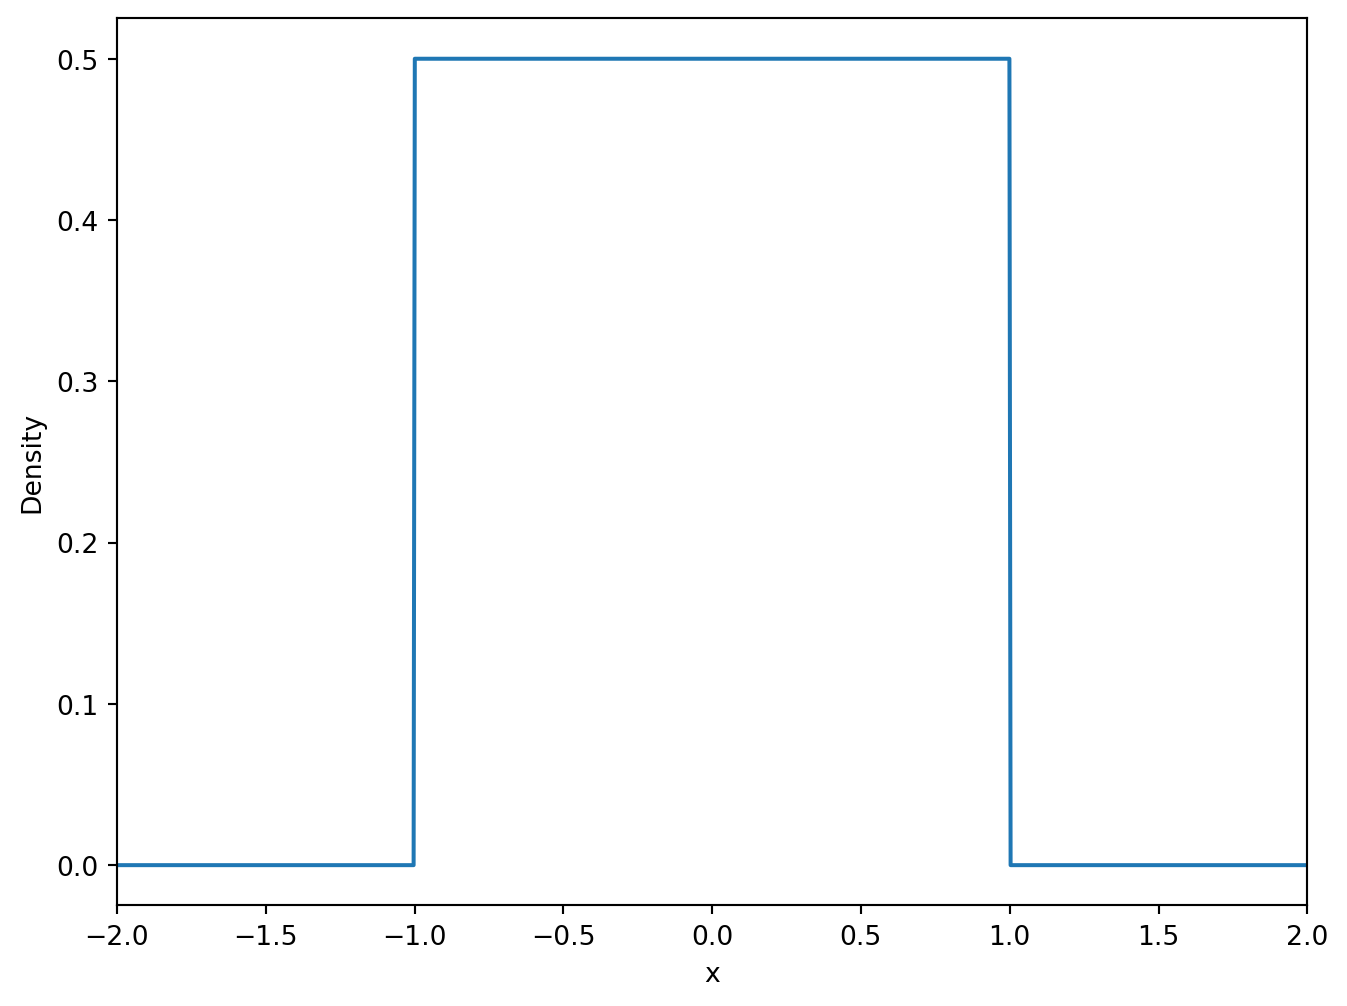

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Define the range of x
x = np.linspace(-2, 2, 1000)

# Calculate the density of the uniform distribution
y = stats.uniform.pdf(x, loc=-1, scale=2)


# Create the plot
plt.figure(figsize=(8, 6))
plt.plot(x, y)
plt.xlim([-2, 2])
plt.xlabel('x')
plt.ylabel('Density')

In [2]:
# Draw 10 random values from the uniform distribution between -1 and 1

x_unif = np.random.uniform(low=-1, high=1, size=10)
x_unif

array([-0.984619  , -0.80926877,  0.61857905,  0.51996657, -0.0984516 ,
        0.86053551, -0.16121936,  0.15748596, -0.77144157,  0.67124826])

In [3]:
# How many of the random numbers are smaller than 0? Use np.sum to count the number of random numbers that satisfy the condition.

print("Number of results less than zero =", np.sum(x_unif < 0))

# How many of the random numbers are between 0 and 0.5?

print("Number of results between 0 and 0.5 =", np.sum((x_unif > 0) & (x_unif < 0.5)))

Number of results less than zero = 5
Number of results between 0 and 0.5 = 1


In [4]:
# Calculate the probability of X being less than 0. (https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.uniform.html)

print("P(X < 0) =", stats.uniform.cdf(0, loc=-1, scale=2))


# Calculate the probability of X being greater than 0.5.

print("P(X > 0.5) =", 1 - stats.uniform.cdf(0.5, loc=-1, scale=2))

# Calculate the probability that the event X is in the interval [0, 0.5] occurs.

print("P(0 < X < 0.5) =", stats.uniform.cdf(0.5, loc=-1, scale=2) - stats.uniform.cdf(0, loc=-1, scale=2))

# Compare the probability with the number of values in the simulation that lie in the interval [0, 0.5].

print("Number of values in the interval [0, 0.5]:", np.sum((x_unif > 0) & (x_unif < 0.5)))

print("Share of values in the interval [0, 0.5]:", np.mean((x_unif > 0) & (x_unif < 0.5)))

P(X < 0) = 0.5
P(X > 0.5) = 0.25
P(0 < X < 0.5) = 0.25
Number of values in the interval [0, 0.5]: 1
Share of values in the interval [0, 0.5]: 0.1


Text(0, 0.5, 'Density')

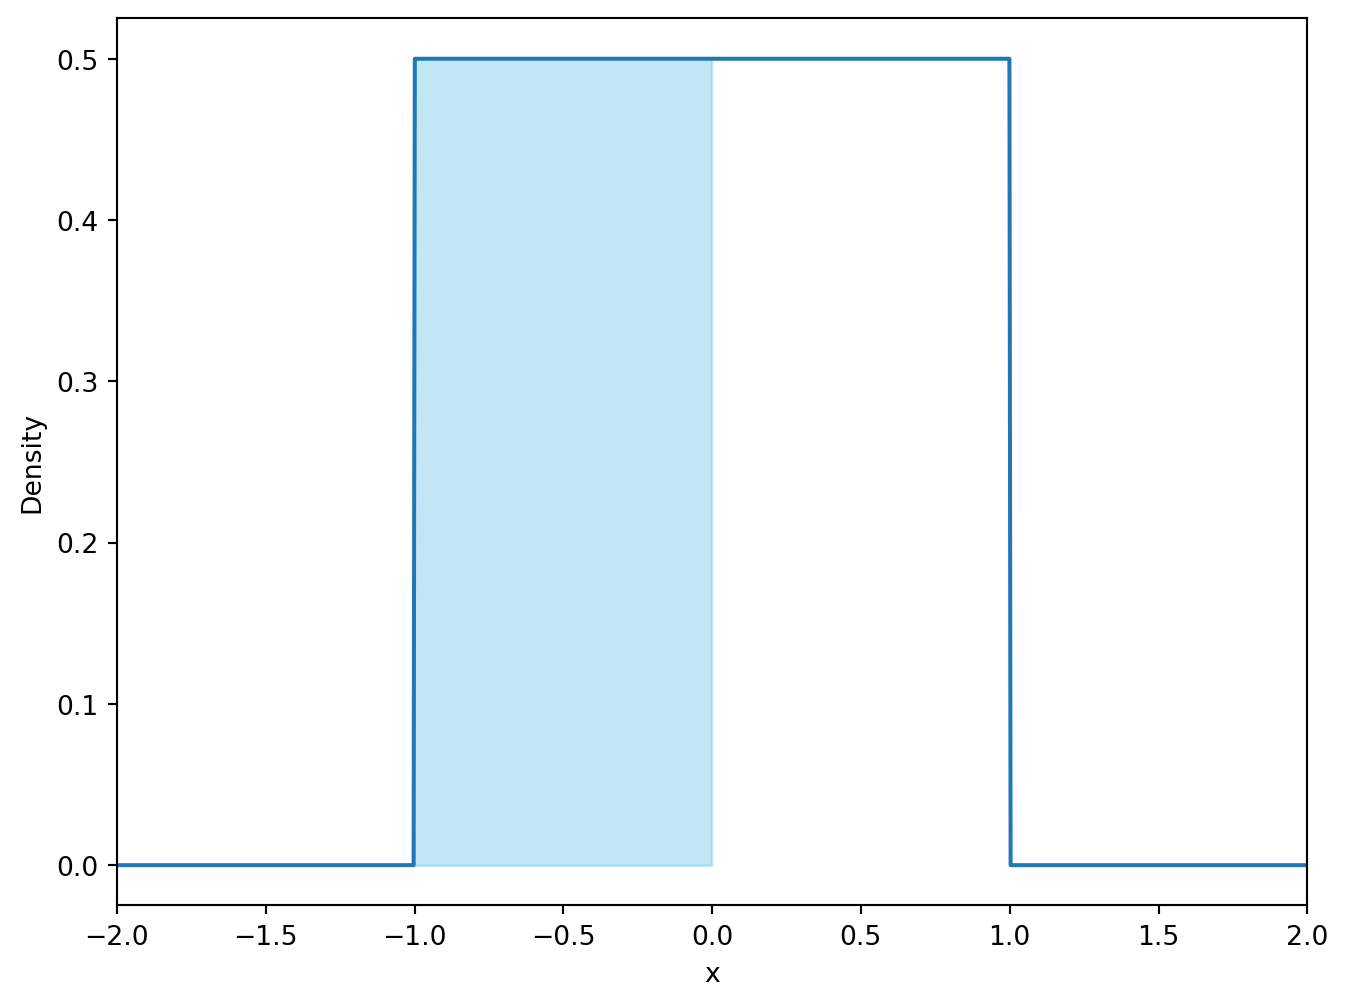

In [5]:
# Visualize the probability of X being less than 0 as the area under the curve.

plt.figure(figsize=(8, 6))
plt.plot(x, y)
plt.fill_between(x, y, where=(x < 0), color='skyblue', alpha=0.5)
plt.xlim([-2, 2])
plt.xlabel('x')
plt.ylabel('Density')


Text(0, 0.5, 'Density')

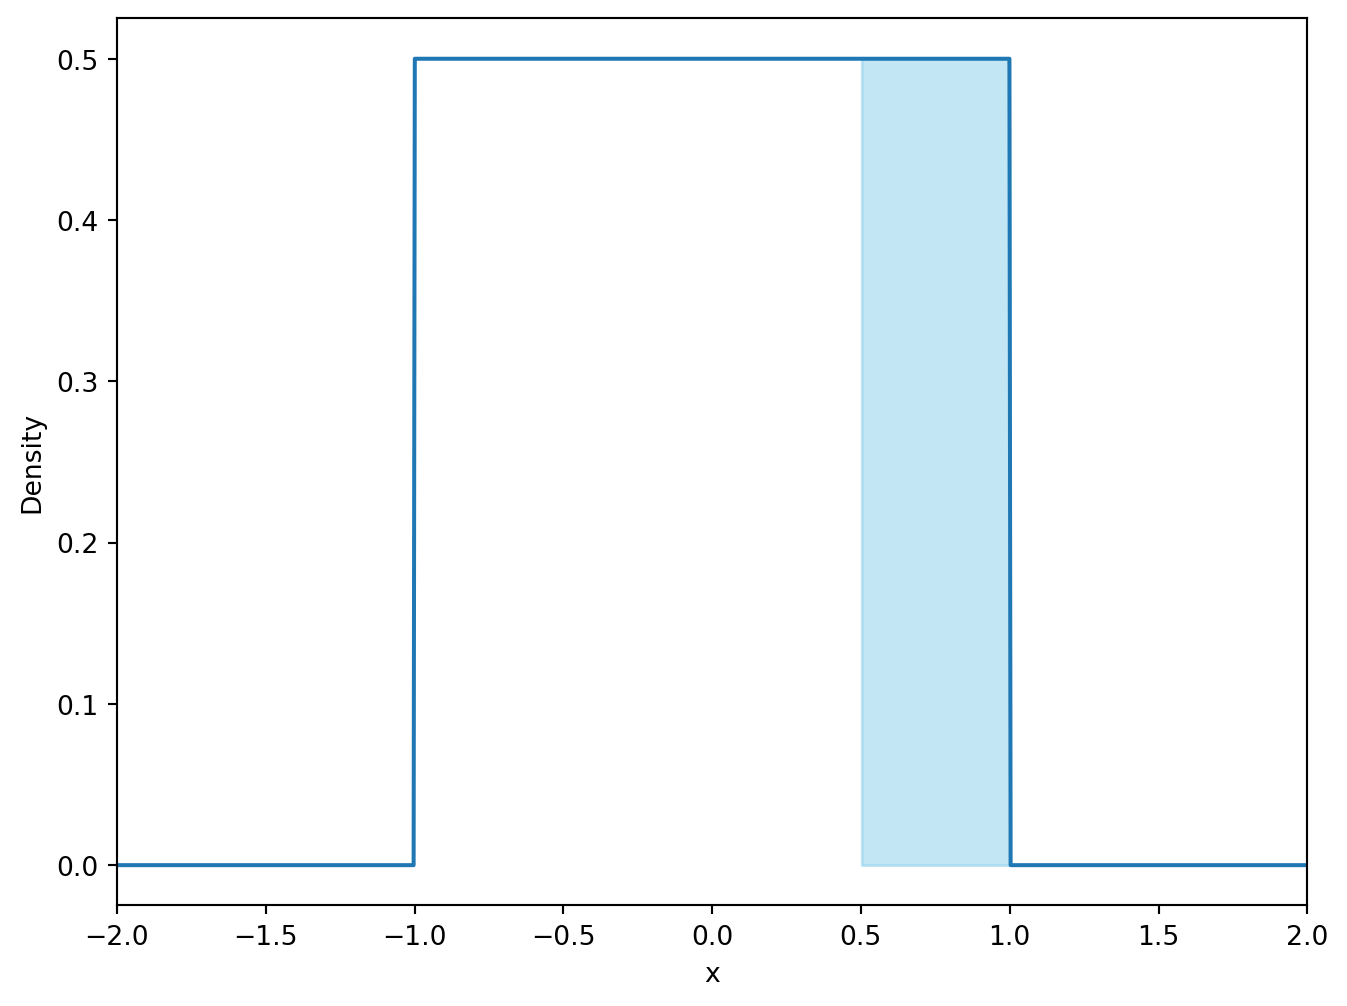

In [6]:
# Visualize the probability of X being greater than 0.5 as the area under the curve.

plt.figure(figsize=(8, 6))
plt.plot(x, y)
plt.fill_between(x, y, where=(x > 0.5), color='skyblue', alpha=0.5)
plt.xlim([-2, 2])
plt.xlabel('x')
plt.ylabel('Density')


Text(0, 0.5, 'Density')

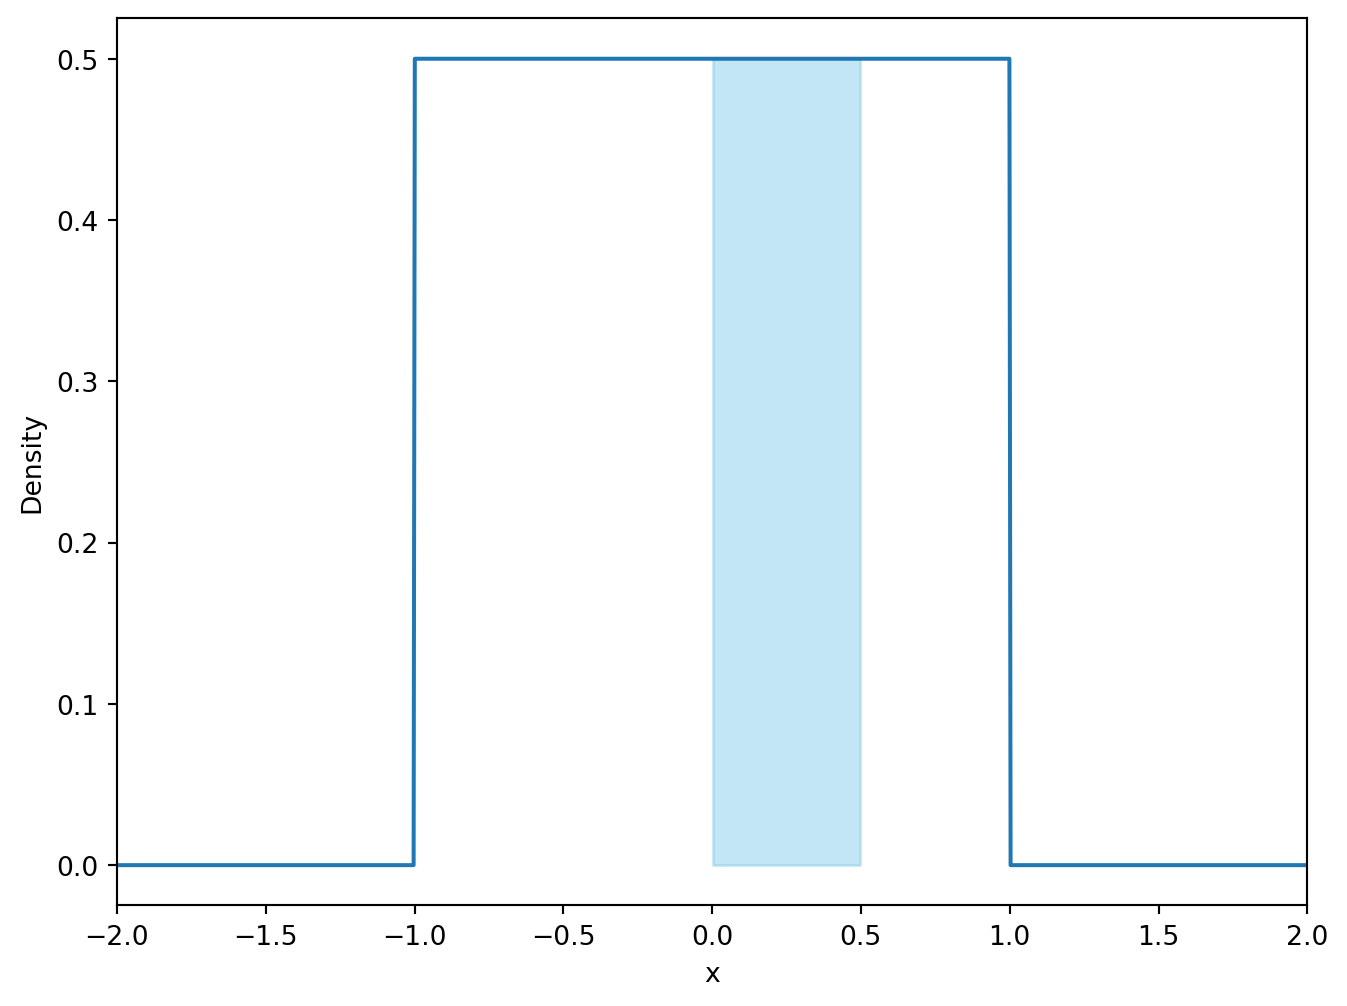

In [7]:
# Visualize the probability of X being in the interval [0, 0.5] as the area under the curve.

plt.figure(figsize=(8, 6))
plt.plot(x, y)
plt.fill_between(x, y, where=((x > 0) & (x < 0.5)), color='skyblue', alpha=0.5)
plt.xlim([-2, 2])
plt.xlabel('x')
plt.ylabel('Density')


## Moments of a Continuous Distribution

:::{#exm-uniform-distribution}
## Moments of the Uniform Distribution

The density function of the uniform distribution on an interval $[a, b], a < b$ is:

$$
f(x) = \begin{cases}
\frac{1}{b - a} & a \leq x \leq b\\
0 & \text{otherwise}
\end{cases}
$$

The expected value is:

$$
\begin{align*}
E(X) & = \int_{-\infty}^{\infty} x \frac{1}{b - a} dx \\
     & = \int_{a}^{b} x \frac{1}{b - a} dx \\
     & = \frac{1}{b - a} \frac{1}{2} x^2 \Big|_{a}^{b} \\
     & = \frac{1}{b - a} \frac{1}{2} (b^2 - a^2) \\
     & = \frac{1}{\cancel{b - a}} \frac{1}{2} (\cancel{b - a})(b + a) \\
     & = \frac{1}{2} (a + b)
\end{align*}
$$

We can obtain the variance using the formula $Var(X) = E(X^2) - E(X)^2$: The expected value of $X^2$ is:

$$
\begin{align*}
E(X^2) & = \int_{-\infty}^{\infty} x^2 \frac{1}{b - a} dx \\
       & = \int_{a}^{b} x^2 \frac{1}{b - a} dx \\
       & = \frac{1}{b - a} \frac{1}{3} x^3 \Big|_{a}^{b} \\
       & = \frac{1}{b - a} \frac{1}{3} (b^3 - a^3) \\
       & = \frac{1}{b - a} \frac{1}{3} (b - a)(b^2 + ab + a^2) \\
       & = \frac{1}{3} (b^2 + ab + a^2)
\end{align*}
$$

The variance is then:

$$
\begin{align*}
Var(X) & = E(X^2) - E(X)^2 \\
       & = \frac{1}{3} (b^2 + ab + a^2) - \left(\frac{1}{2} (a + b)\right)^2 \\
       & = \frac{1}{3} (b^2 + ab + a^2) - \frac{1}{4} (a^2 + 2ab + b^2) \\
       & = \frac{1}{3} b^2 + \frac{1}{3} ab + \frac{1}{3} a^2 - \frac{1}{4} a^2 - \frac{1}{2} ab - \frac{1}{4} b^2 \\
       & = \frac{1}{12} b^2 - \frac{1}{6} ab + \frac{1}{12} a^2 \\
       & = \frac{1}{12} (b - a)^2
\end{align*}
$$




:::

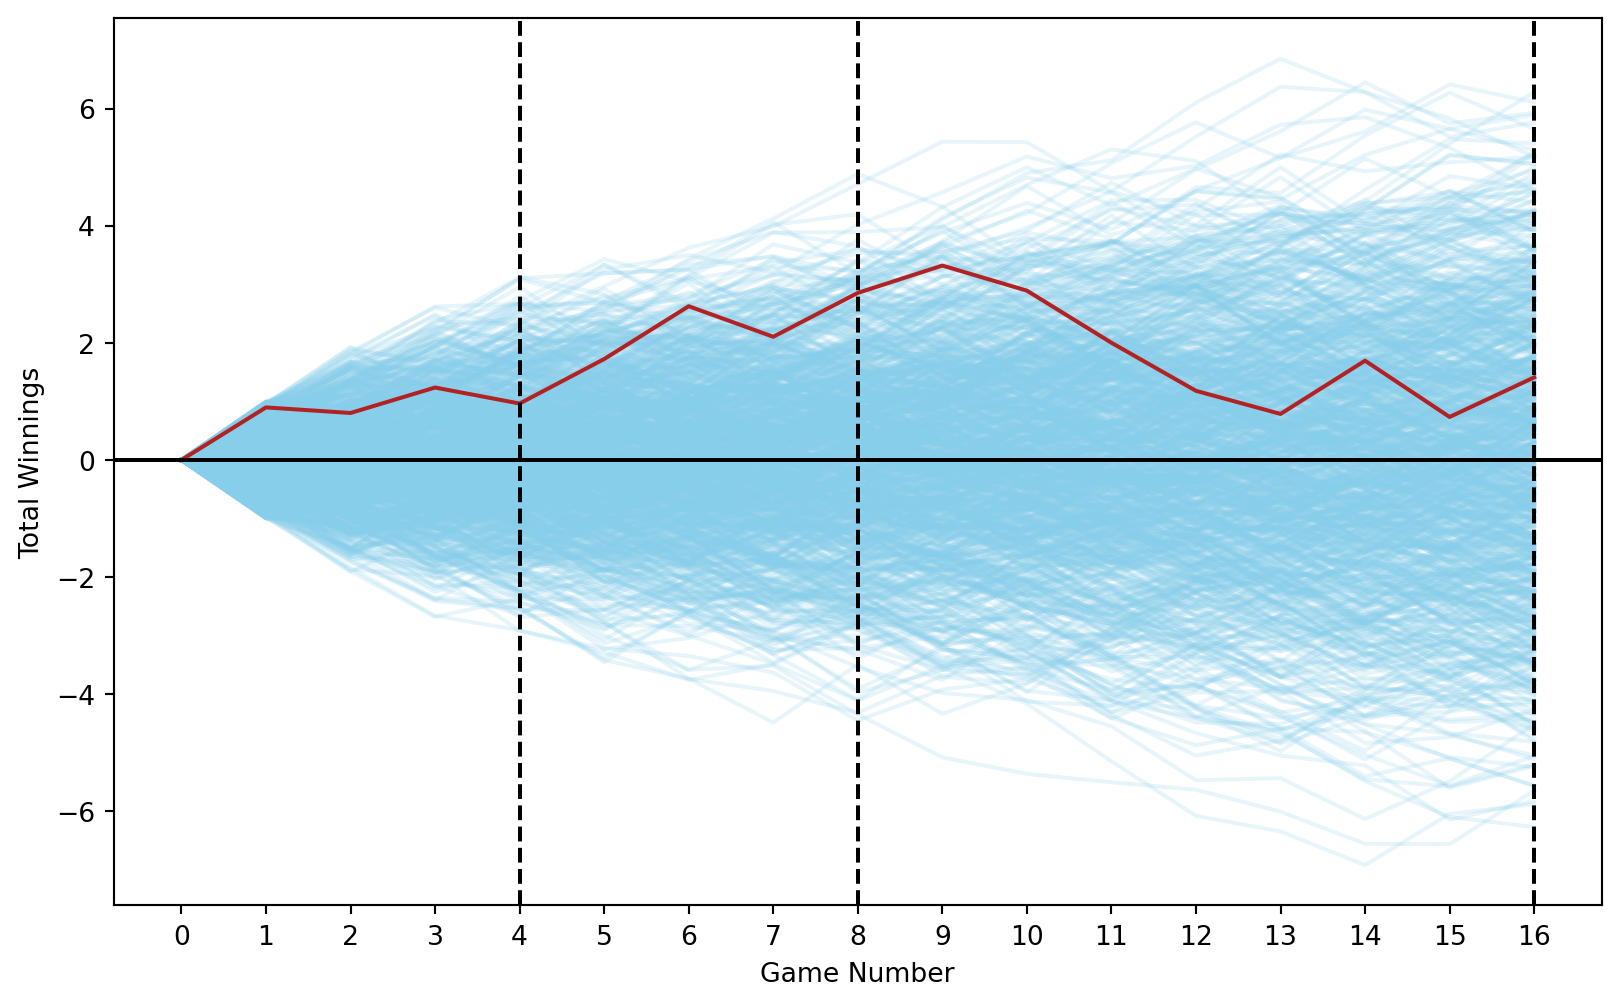

In [8]:
players_n = 1000
games_n = 16

# Create a DataFrame similar to expand_grid in R
unif_games = pd.DataFrame(
    np.array(
        np.meshgrid(
            np.arange(1, games_n + 1),
            np.arange(1, players_n + 1)
        )).T.reshape(-1, 2),
    columns=['game', 'player']
)

# Add result column with random uniform values between -1 and 1
unif_games['result'] = np.random.uniform(-1, 1, size=len(unif_games))

# Add initial values for each player
initial_values = pd.DataFrame(
    {'player': np.arange(1, players_n + 1), 'game': 0, 'result': 0})
unif_games = pd.concat([unif_games, initial_values])

# Sort values and calculate running total for each player
unif_games = unif_games.sort_values(['player', 'game'])
unif_games['running_total'] = unif_games.groupby('player')['result'].cumsum()

# Plotting
plt.figure(figsize=(10, 6))
for player in unif_games['player'].unique():
    player_data = unif_games[unif_games['player'] == player]
    plt.plot(player_data['game'], player_data['running_total'],
             color='skyblue', alpha=0.2)

# First player
player_data = unif_games[unif_games['player'] == 1]
plt.plot(player_data['game'], player_data['running_total'],
         color='firebrick', label='Player 1')

plt.axhline(0, color='black')

for mark in [4, 8, 16]:
    plt.axvline(x=mark, linestyle='--', color='black')

plt.xlabel('Game Number')
plt.ylabel('Total Winnings')
plt.xticks(range(0, 17, 1))
plt.show()

Text(0.5, 0, 'Running total')

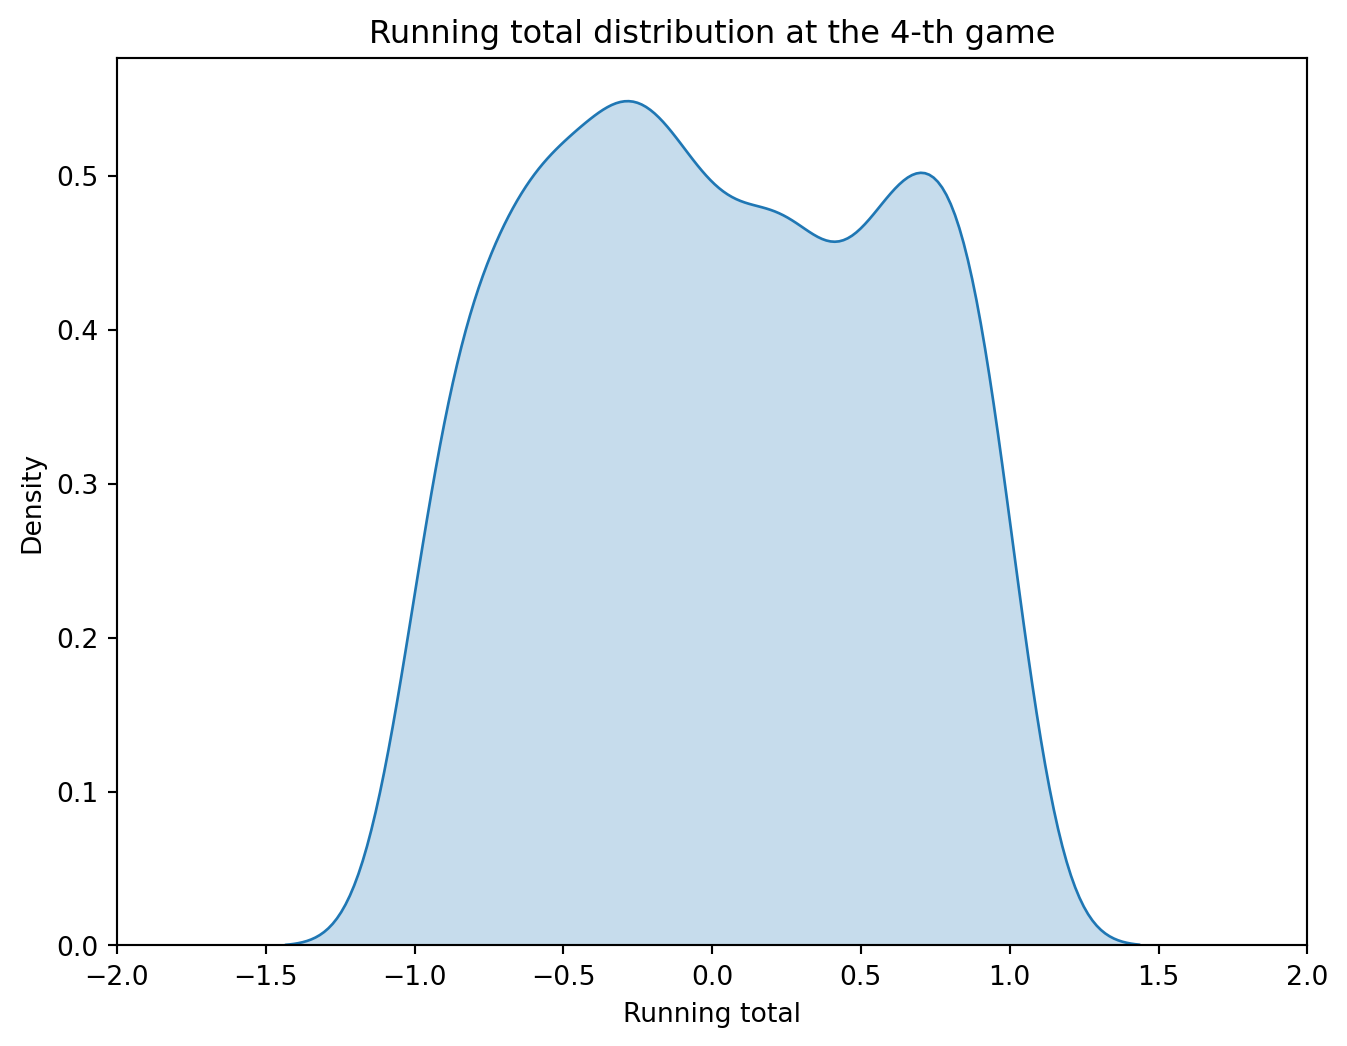

In [9]:
game_4 = unif_games[unif_games['game'] == 1]

plt.figure(figsize=(8, 6))
sns.kdeplot(data=game_4, x='running_total', fill=True)
plt.xlim((-2, 2))
plt.title('Running total distribution at the 4-th game')
plt.xlabel('Running total')

## The Normal Distribution

Text(0, 0.5, 'Density')

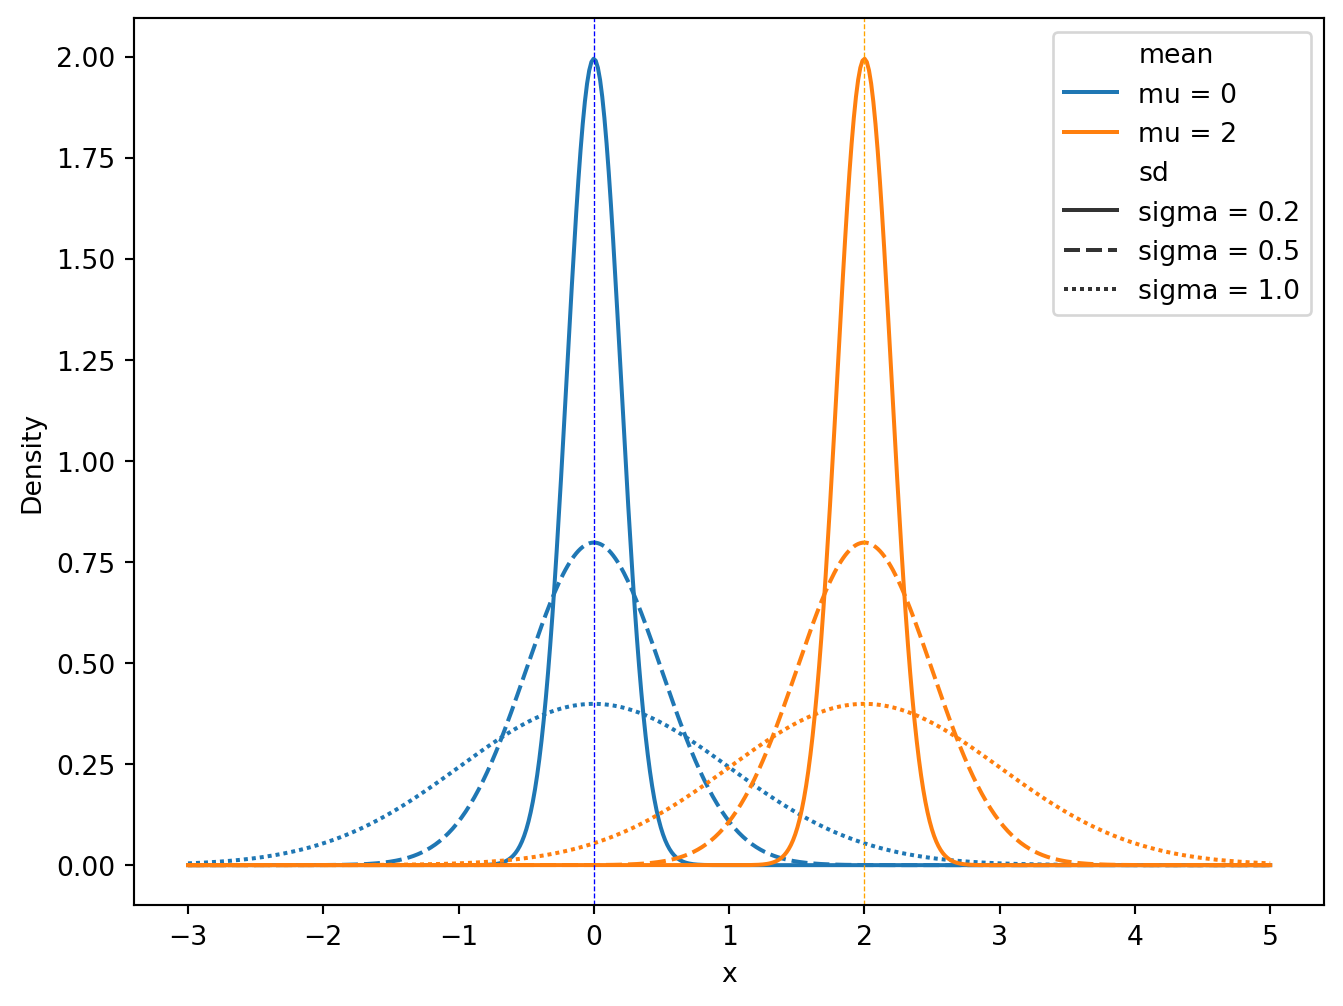

In [10]:
# Visualize the density of the normal distribution with different means and standard deviations

# Define the means and standard deviations for which we want to plot the normal distribution

means = [0, 2]
sds = [0.2, 0.5, 1]

# Create a grid of x values
x = np.linspace(-3, 5, 500)

# Create a DataFrame with all combinations of means, sds, and x values
df = pd.DataFrame([(mean, sd, x_val, stats.norm.pdf(x_val, mean, sd)) 
                   for mean in means for sd in sds for x_val in x], 
                  columns=['mean', 'sd', 'x', 'y'])

# Create labels for mean and sd
df['mean'] = r'mu = ' + df['mean'].astype(str)
df['sd'] = r'sigma = ' + df['sd'].astype(str)

# Plot
plt.figure(figsize=(8, 6))
sns.lineplot(data=df, x='x', y='y', hue='mean', style='sd')
plt.axvline(0, color='blue', linestyle='--', linewidth=0.5)
plt.axvline(2, color='orange', linestyle='--', linewidth=0.5)
plt.xlabel('x')
plt.ylabel('Density')

:::{.callout-important}
## Properties of the Normal Distribution


$$
\begin{align*}
E(X) & = \mu \\
Var(X) & = \sigma^2
\end{align*}
$$

If $X \sim N(\mu, \sigma^2)$, then $Z = \frac{X - \mu}{\sigma} \sim N(0, 1)$ is called the standard normal distribution. The standard normal distribution has mean 0 and variance 1.

If $X_1, X_2, \ldots, X_n$ are independent and identically distributed (i.i.d.) random variables with mean $\mu$ and variance $\sigma^2$, then sum of the random variables is normally distributed:

$$
\sum_{i=1}^{n} X_i \sim N(n\mu, n\sigma^2)
$$

:::

:::{#thm-central-limit-theorem}
## Central Limit Theorem

Let $X_1, X_2, \ldots, X_n$ be i.i.d. random variables with mean $\mu$ and variance $\sigma^2$. Let $S_n = \sum_{i=1}^{n} X_i$. Then, as $n$ approaches infinity, the distribution of $\frac{S_n - n\mu}{\sqrt{n}\sigma}$ approaches the standard normal distribution.

$$
\frac{S_n - n\mu}{\sqrt{n}\sigma} \xrightarrow{d} N(0, 1)
$$

:::

## Normal Distribution (Probabilities)

:::{.callout-importnat}
## Standardizing a Random Variable

For any random variable with expected value \(\mu\) and variance \(\sigma^2\), we can standardize the random variable by subtracting the mean and dividing by the standard deviation:

$$
Z = \frac{X - \mu}{\sigma}
$$

The resulting random variable \(Z\) has mean 0 and variance 1. To see this, simply calculate the expected value and variance of \(Z\):

$$
\begin{align*}
E(Z) & = E\left(\frac{X - \mu}{\sigma}\right) = \frac{E(X) - \mu}{\sigma} = 0 \\
Var(Z) & = Var\left(\frac{X - \mu}{\sigma}\right) = \frac{Var(X)}{\sigma^2} = 1
\end{align*}
$$

Note that $\mu$ and $\sigma$ are not random variables but constants.

:::

:::{#exr-normal-distribution-probabilities}
## Probabilities with the Normal Distribution

Calculate the following probabilities for the standard normal distribution. Let the level of a river be normally distributed with mean 7 (meters) and standard deviation ($\sigma$) 1.5. Let us say that the river is in flood when the level is above 9 meters and in drought when the level is below 5 meters.

1. What is the probability that the river is in flood?
2. What is the probability that the river is in drought?
3. What is the probability that the river is between 5 and 9 meters?

:::

:::{.callout-note collapse="true"}
## Solution (click to expand)

1. The probability that the river is in flood is given by:

$$
P(X > 9) = 1 - P(X \leq 9) = 1 - F(9)
$$

where \(F(x)\) is the CDF of the normal distribution. With access to computer software, we can compute the CDF directly (see the result below). If you must use a z-table, you need to standardize first:

$$
P(X > 9) = 1 - P\left(\frac{X - 7}{1.5} \leq \frac{9 - 7}{1.5}\right) = 1 - P(Z \leq 1.33) = 1 - 0.90878 = 0.09121
$$

:::

In [11]:
# Compute the probabilities with scipy.stats

# Probability that the river level is over 9 meters. In the following code loc is the mean and scale is the standard deviation.

print(1 - stats.norm.cdf(9, loc=7, scale=1.5))

# The same probability using the standard normal distribution

print(1 - stats.norm.cdf((9 - 7) / 1.5))

0.09121121972586788
0.09121121972586788


Text(0.5, 1.0, 'P(X > 9) = 0.0912')

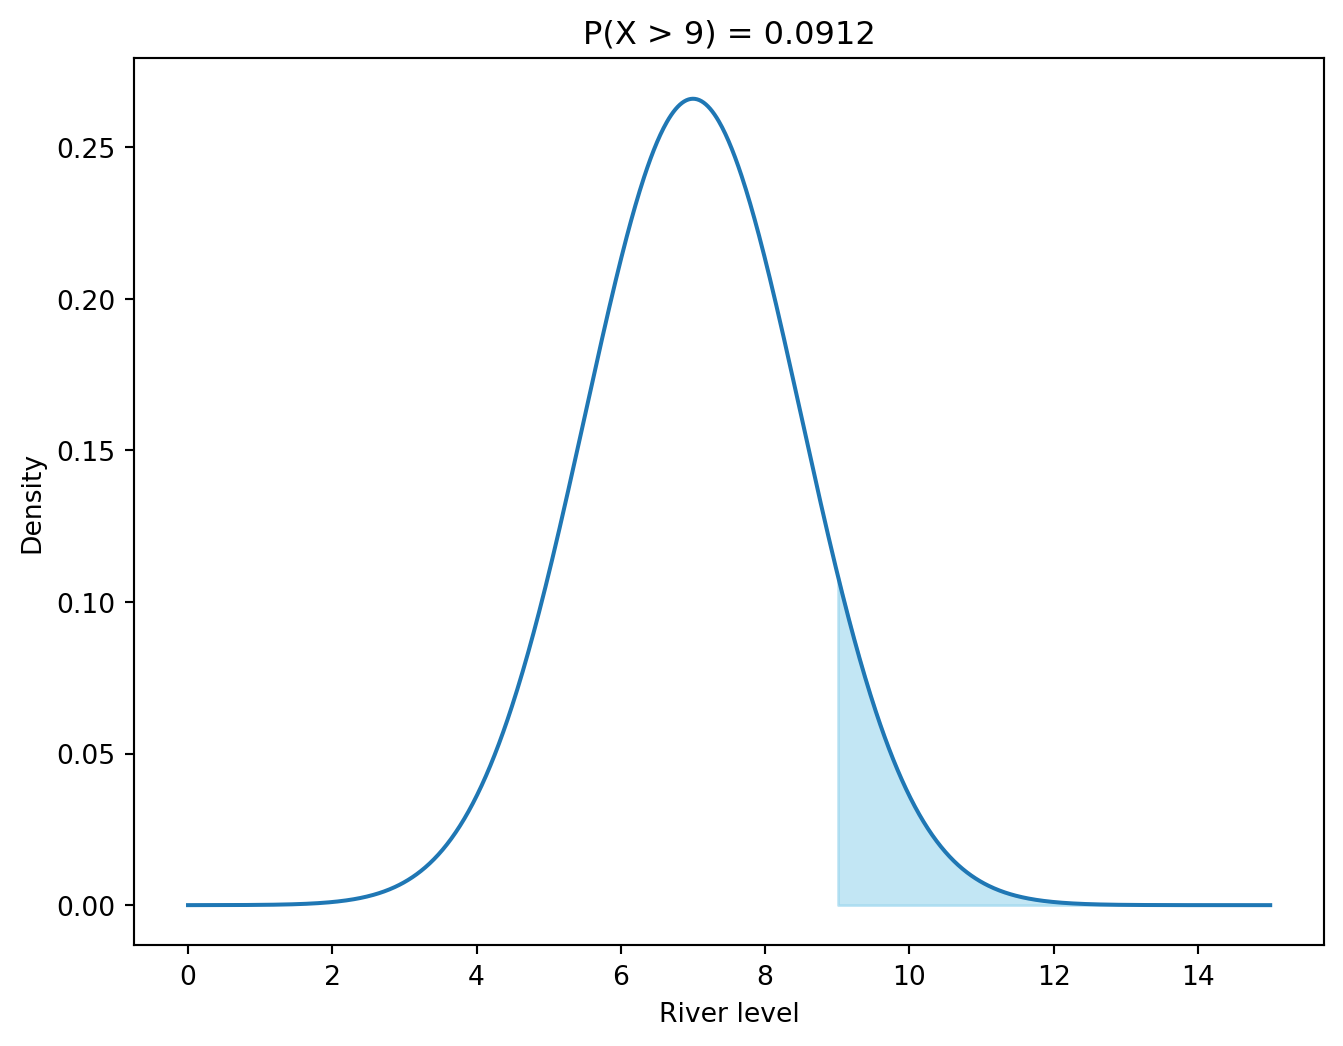

In [12]:
# Show the probability as an area under the curve

x = np.linspace(0, 15, 1000)

y = stats.norm.pdf(x, loc=7, scale=1.5)

plt.figure(figsize=(8, 6))
plt.plot(x, y)
plt.fill_between(x, y, where=(x > 9), color='skyblue', alpha=0.5)
plt.xlabel('River level')
plt.ylabel('Density')
plt.title('P(X > 9) = 0.0912')

In [13]:
# Probability that the river is in drought (below 6 meters).

print(stats.norm.cdf(6, loc=7, scale=1.5))

# The same probability using the standard normal distribution.

print(stats.norm.cdf((6 - 7) / 1.5))

0.2524925375469229
0.2524925375469229


Text(0.5, 1.0, 'P(X < 6) = 0.25249')

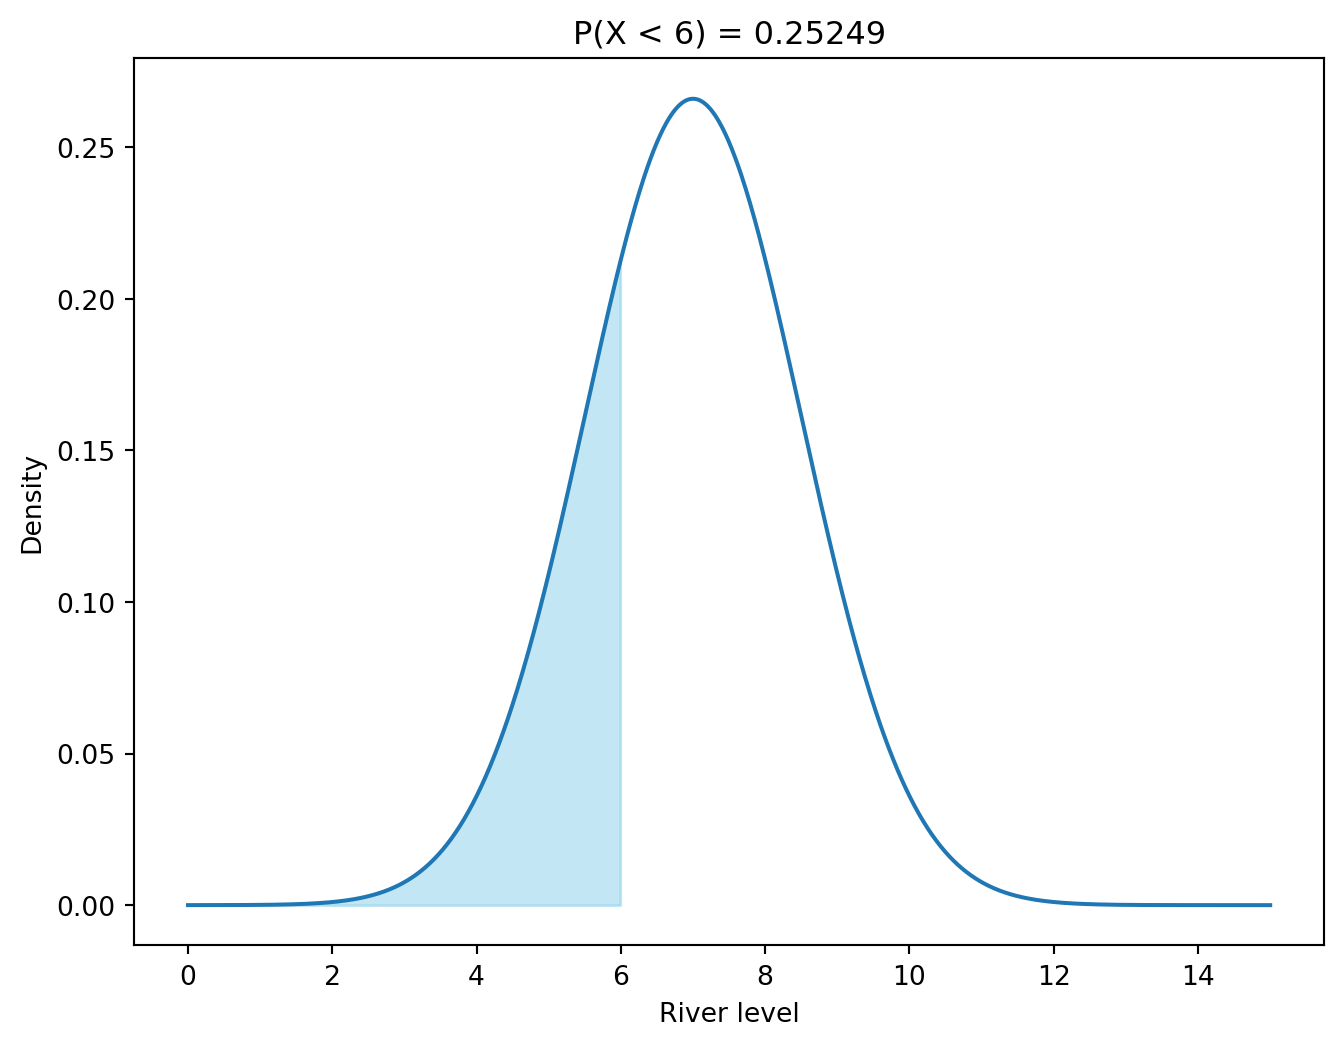

In [14]:
x = np.linspace(0, 15, 1000)

y = stats.norm.pdf(x, loc=7, scale=1.5)

plt.figure(figsize=(8, 6))
plt.plot(x, y)
plt.fill_between(x, y, where=(x < 6), color='skyblue', alpha=0.5)
plt.xlabel('River level')
plt.ylabel('Density')
plt.title('P(X < 6) = 0.25249')

In [15]:
# Probability that the river level is between 6 and 9 meters (not in drought and not in flood)

print(stats.norm.cdf(9, loc=7, scale=1.5) - stats.norm.cdf(6, loc=7, scale=1.5))

# The same probability, calculated using the standard normal distribution

print(stats.norm.cdf((9 - 7) / 1.5) - stats.norm.cdf((6 - 7) / 1.5))


0.6562962427272092
0.6562962427272092


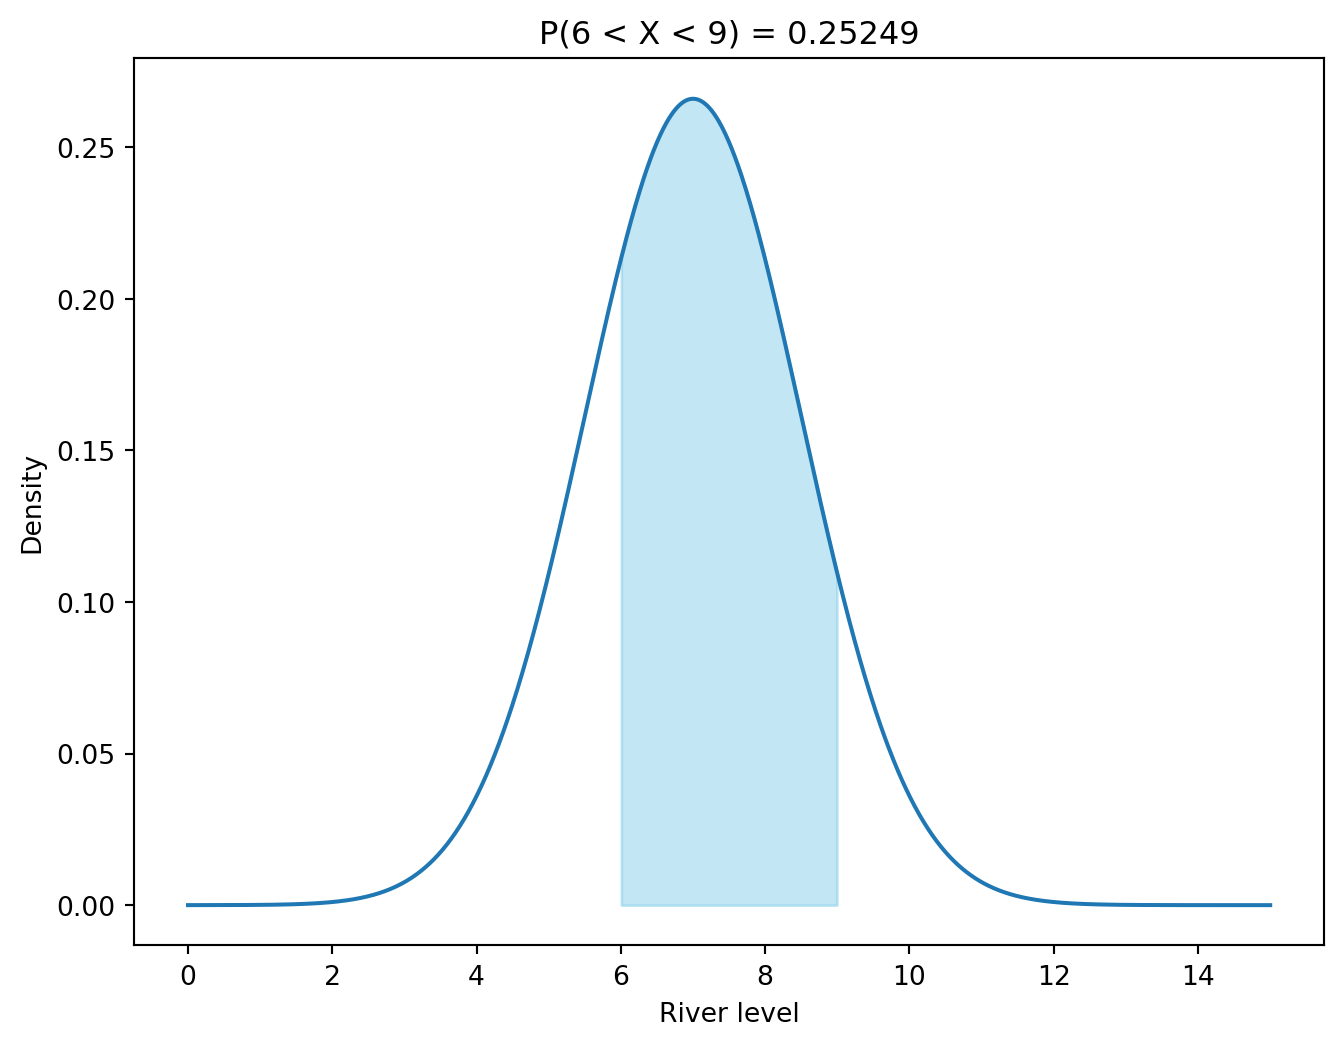

In [16]:
x = np.linspace(0, 15, 1000)

y = stats.norm.pdf(x, loc=7, scale=1.5)

plt.figure(figsize=(8, 6))
plt.plot(x, y)
plt.fill_between(x, y, where=(x > 6) & (x < 9), color='skyblue', alpha=0.5)
plt.xlabel('River level')
plt.ylabel('Density')
plt.title('P(6 < X < 9) = 0.25249')
plt.show()

In [17]:
# Create a z-table for the 

import pandas as pd
import numpy as np
from scipy.stats import norm

# Define the range of z-scores
z_scores = np.arange(-3.0, 3.1, 0.1)

# Calculate the probabilities for each z-score
probabilities = norm.cdf(z_scores)

# Create a DataFrame
df = pd.DataFrame({
    'z': z_scores,
    'P(x < Z)': probabilities
})

df

,z,P(x < Z)
0,-3.0,0.001350
1,-2.9,0.001866
2,-2.8,0.002555
3,-2.7,0.003467
4,-2.6,0.004661
...,...,...
56,2.6,0.995339
57,2.7,0.996533
58,2.8,0.997445
59,2.9,0.998134


## Standard Deviation and Probability

In [18]:
# See this with code
# Run the code for different value of mu and sd and see that the probabilities don't change

mu = 70
sd = 10

# One sigma above and below the mean
print(stats.norm.cdf(mu + sd, loc=mu, scale=sd) - stats.norm.cdf(mu - sd, loc=mu, scale=sd))

# Two sigma above and below the mean
print(stats.norm.cdf(mu + 2*sd, loc=mu, scale=sd) - stats.norm.cdf(mu - 2*sd, loc=mu, scale=sd))

# Three sigma above and below the mean
print(stats.norm.cdf(mu + 3*sd, loc=mu, scale=sd) - stats.norm.cdf(mu - 3*sd, loc=mu, scale=sd))


0.6826894921370859
0.9544997361036416
0.9973002039367398


Text(0.5, 1.0, '$P(\\mu - \\sigma < X < \\mu + \\sigma) \\approx 0.68$, $P(\\mu - 2\\sigma < X < \\mu + 2\\sigma) \\approx 0.95$')

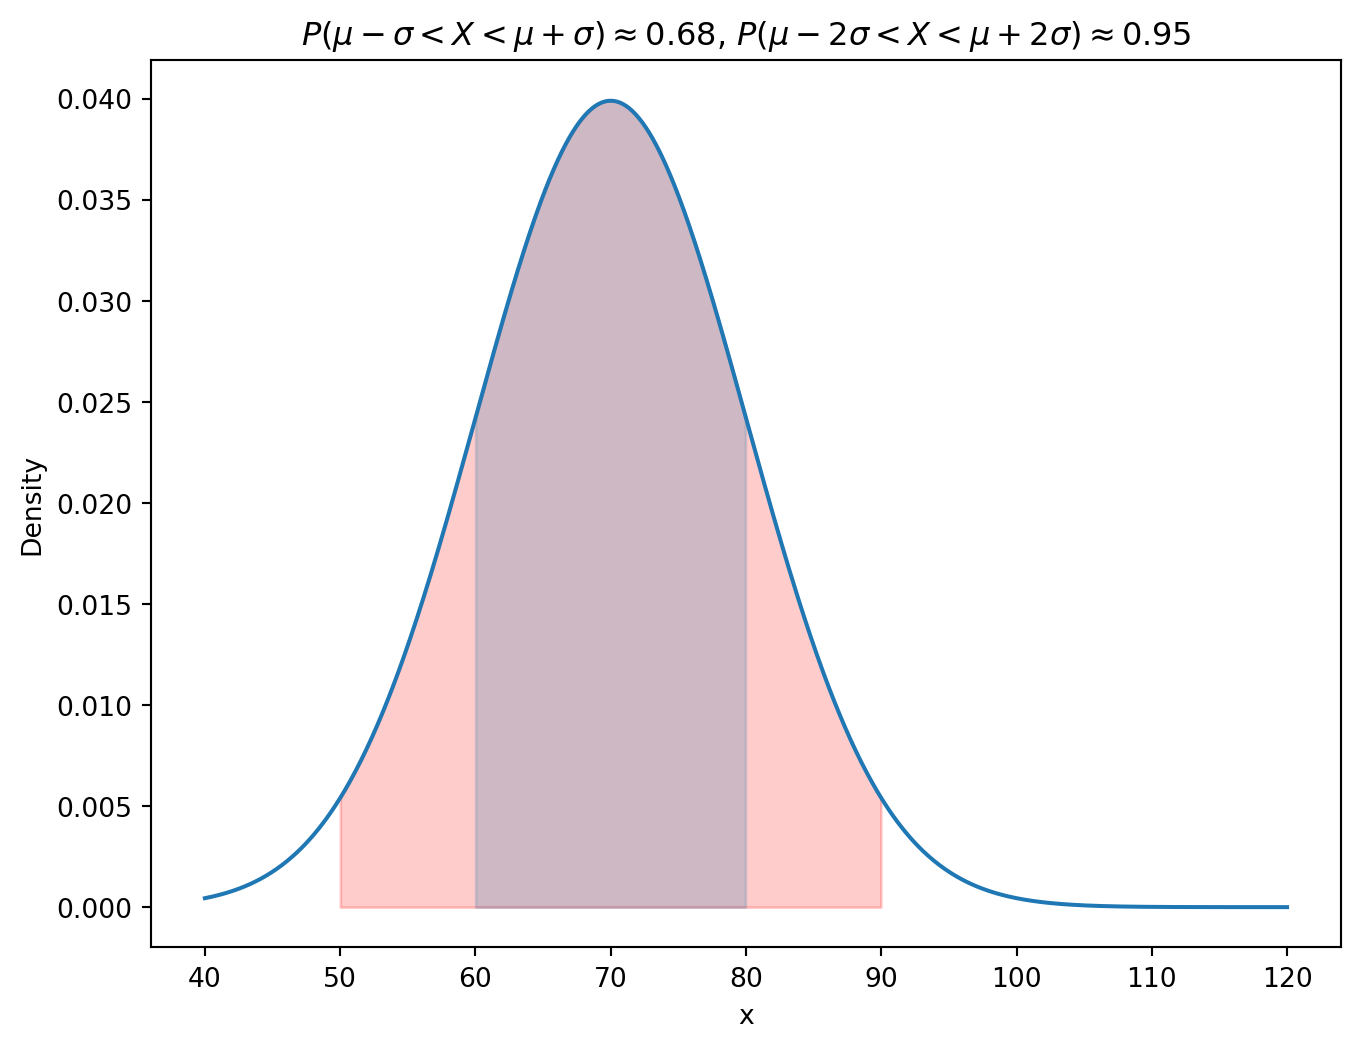

In [19]:
# Visualize the probability for one sigma above and below the mean

x = np.linspace(40, 120, 1000)
y = stats.norm.pdf(x, loc=mu, scale=sd)

plt.figure(figsize=(8, 6))
plt.plot(x, y)
plt.fill_between(x, y, where=((x > mu - sd) & (x < mu + sd)), color='skyblue', alpha=0.5)
plt.fill_between(x, y, where=((x > mu - 2 *sd) & (x < mu + 2 * sd)), color='red', alpha=0.2)
plt.xlabel('x')
plt.ylabel('Density')
plt.title(r'$P(\mu - \sigma < X < \mu + \sigma) \approx 0.68$, $P(\mu - 2\sigma < X < \mu + 2\sigma) \approx 0.95$')


## Quantile Function

:::{#exr-normal-distribution-quantile}
## River Level Quantiles

- Let us continue the example with the river level. What is the level of the river such that the probability of the river being below that level is 0.05 (the 0.05 quantile)?
- What is the level of the river such that the probability of the river being above that level is 0.05 (the 0.95 quantile)?

:::

Text(0.5, 1.0, 'Quantile function of the standard normal distribution')

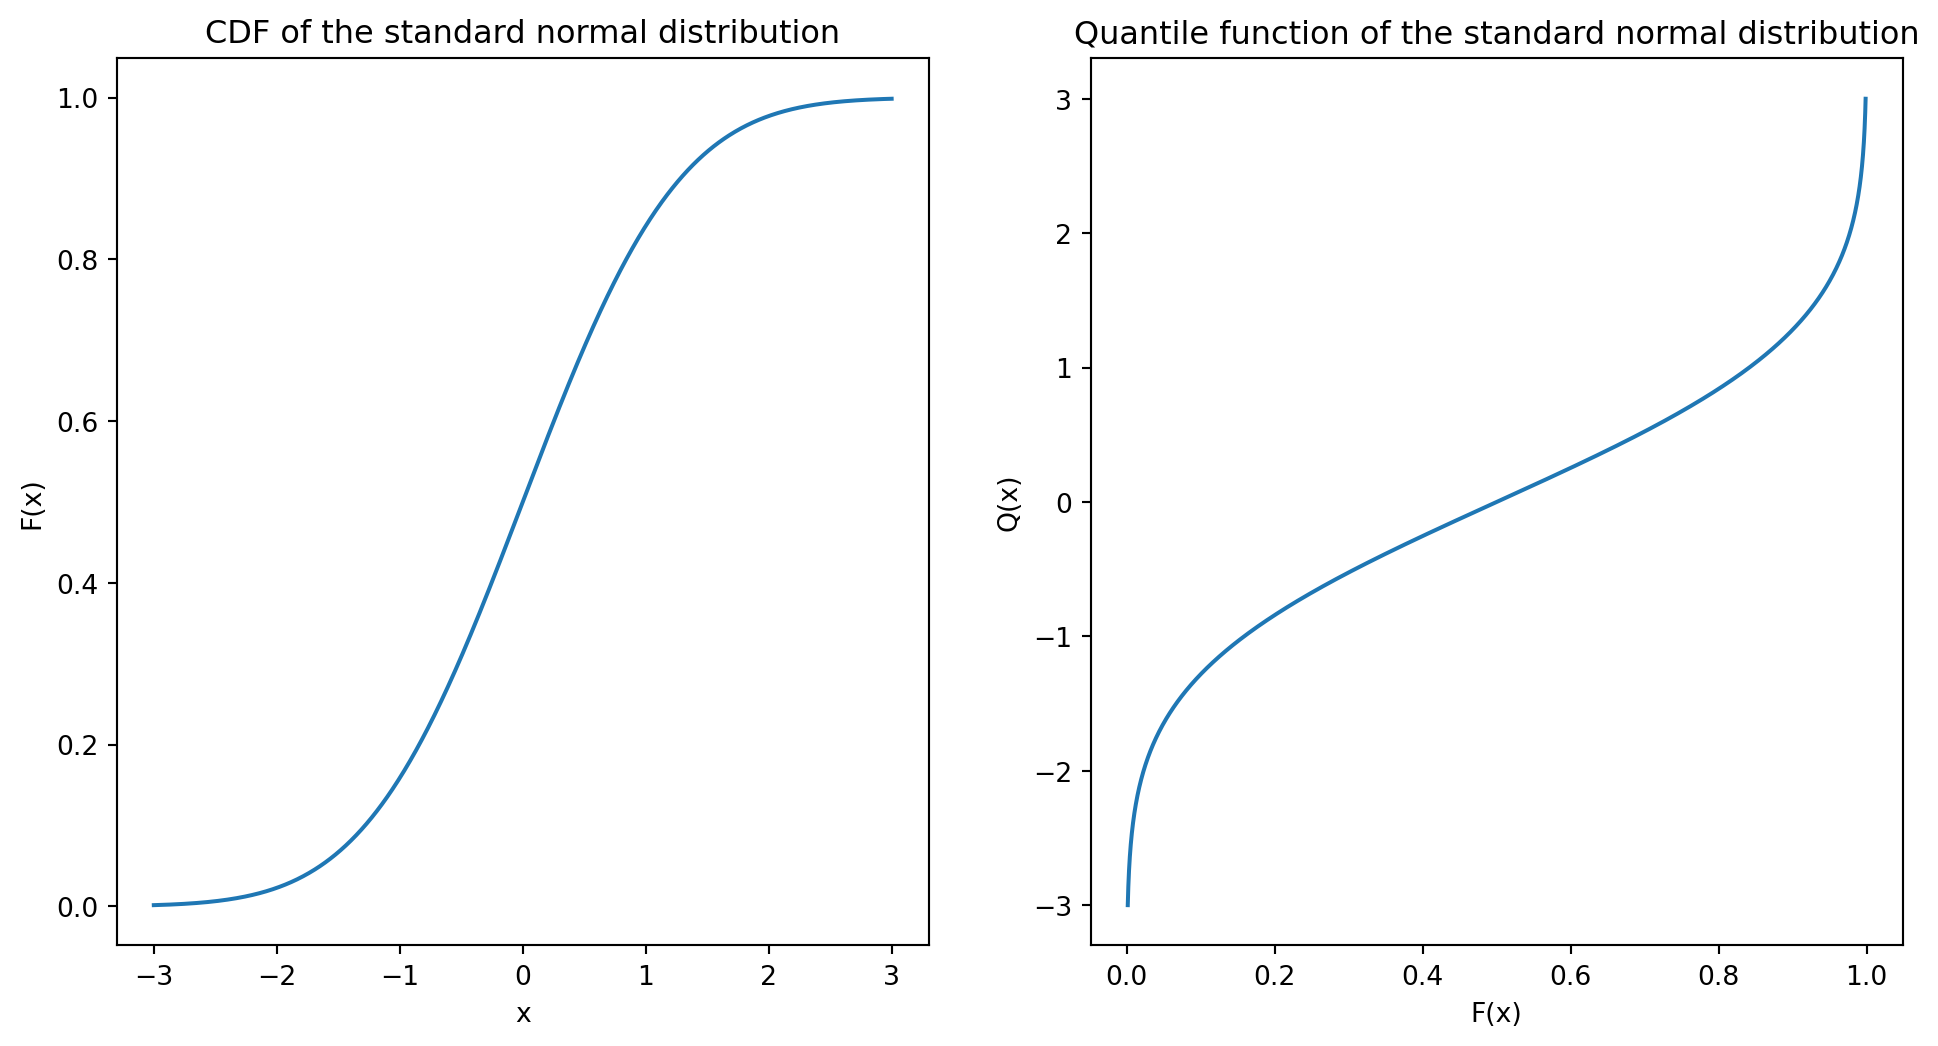

In [20]:
# Plot the CFD and the quantile function for the standard normal distribution

# Create a grid of x values

x = np.linspace(-3, 3, 1000)

# Calculate the CDF of the standard normal distribution

y_cdf = stats.norm.cdf(x)

# Calculate the quantile function of the standard normal distribution

y_quantile = stats.norm.ppf(y_cdf)

# Create the plot

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(x, y_cdf)
plt.xlabel('x')
plt.ylabel('F(x)')
plt.title('CDF of the standard normal distribution')

plt.subplot(1, 2, 2)
plt.plot(y_cdf, x)
plt.xlabel('F(x)')
plt.ylabel('Q(x)')
plt.title('Quantile function of the standard normal distribution')

In [21]:
# Calculate the 0.05 quantile using the quantile function (called ppf (percentage point function) in scipy.stats)

print(stats.norm.ppf(0.05, loc=7, scale=1.5))

print(stats.norm.ppf(0.95, loc=7, scale=1.5))


4.532719559572791
9.467280440427208


Text(0.5, 1.0, 'P(X < 4.5) = 0.05, P(X > 9.5) = 0.05, P(4.5 < X < 9.5) = 0.9')

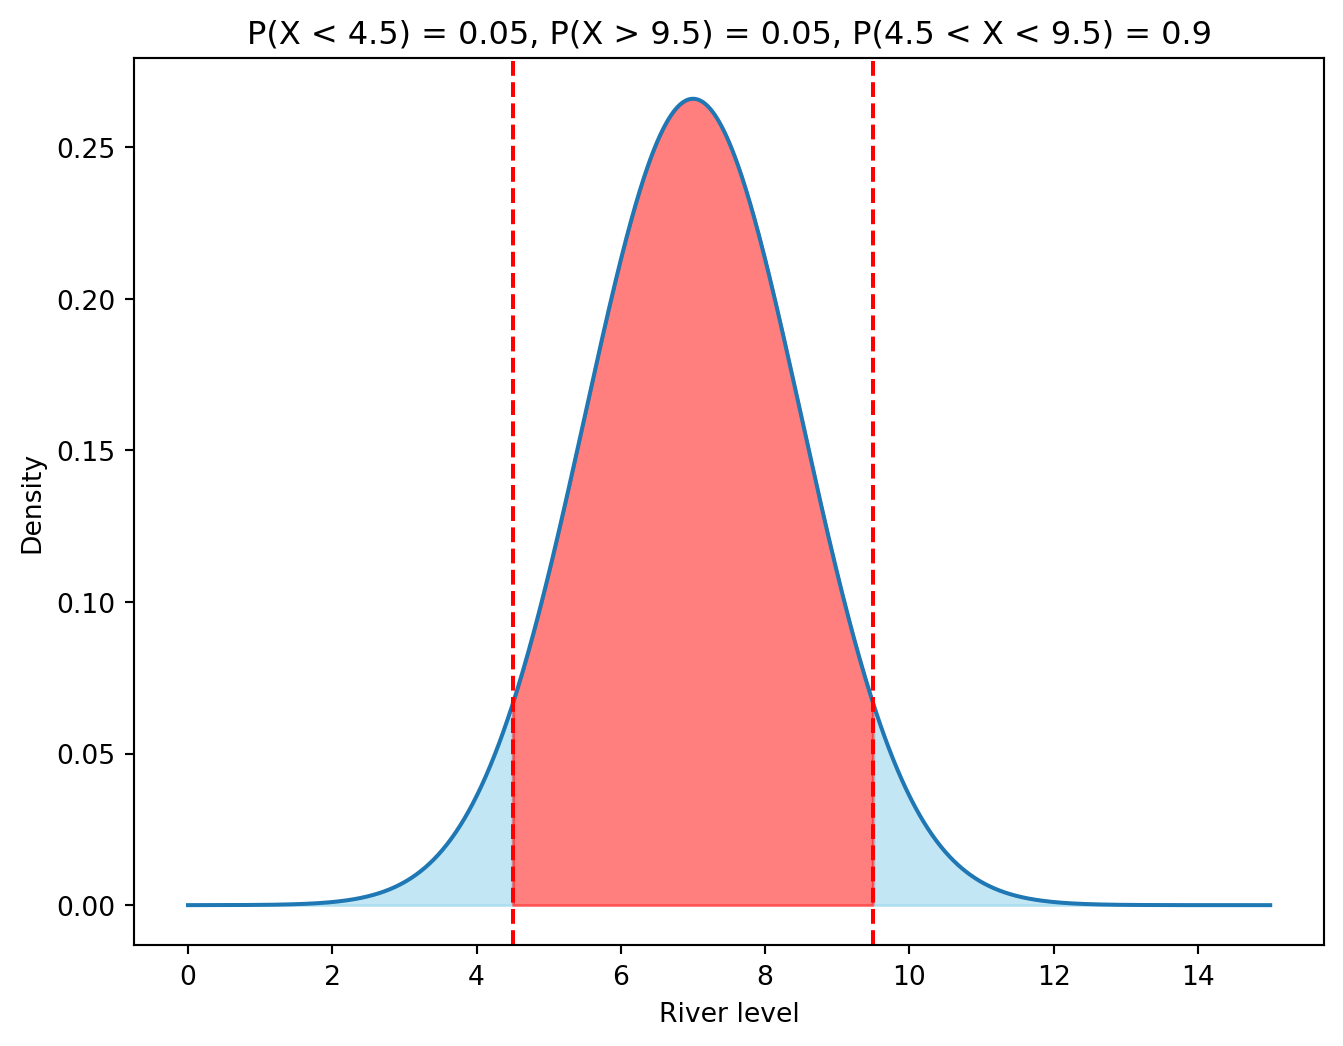

In [22]:
# Visualize the quantiles on the density plot

x = np.linspace(0, 15, 1000)

y = stats.norm.pdf(x, loc=7, scale=1.5)

plt.figure(figsize=(8, 6))
plt.plot(x, y)
plt.fill_between(x, y, where=(x < 4.5), color='skyblue', alpha=0.5)
plt.fill_between(x, y, where=(x > 9.5), color='skyblue', alpha=0.5)
plt.fill_between(x, y, where=(x > 4.5) & (x < 9.5), color='red', alpha=0.5)
plt.axvline(4.5, color='red', linestyle='--')
plt.axvline(9.5, color='red', linestyle='--')
plt.xlabel('River level')
plt.ylabel('Density')
plt.title('P(X < 4.5) = 0.05, P(X > 9.5) = 0.05, P(4.5 < X < 9.5) = 0.9')


In [23]:
# Create a z-table for the quantiles of the standard normal distribution

import pandas as pd
import numpy as np

# Define the range of probabilities

probabilities = np.arange(0.0, 0.11, 0.01)

# Calculate the quantiles for each probability

quantiles = stats.norm.ppf(probabilities)

# Create a DataFrame

df = pd.DataFrame({
    'P(x < Z)': probabilities,
    'Q(p)': quantiles
})

df


,P(x < Z),Q(p)
0,0.00,-inf
1,0.01,-2.326348
2,0.02,-2.053749
3,0.03,-1.880794
4,0.04,-1.750686
5,0.05,-1.644854
6,0.06,-1.554774
7,0.07,-1.475791
8,0.08,-1.405072
9,0.09,-1.340755


In [24]:
# To find the 0.05 quantile of the normal distribution with mean 7 and standard deviation 1.5 using a z-table
# we can first find the corresponding quantile of the standard normal distribution and then transform it back to the original scale.

# Find the 0.05 quantile of the standard normal distribution 

z = stats.norm.ppf(0.05) # You can also look it up in the table above
z

# Transform the quantile back to the original scale

quantile = 7 + 1.5 * z
quantile

np.float64(4.532719559572791)

In [25]:
# Check the result using the quantile function of the normal distribution with mean 7 and standard deviation 1.5

stats.norm.ppf(0.05, loc=7, scale=1.5)

np.float64(4.532719559572791)

## The Standard Normal Distribution and Quantiles

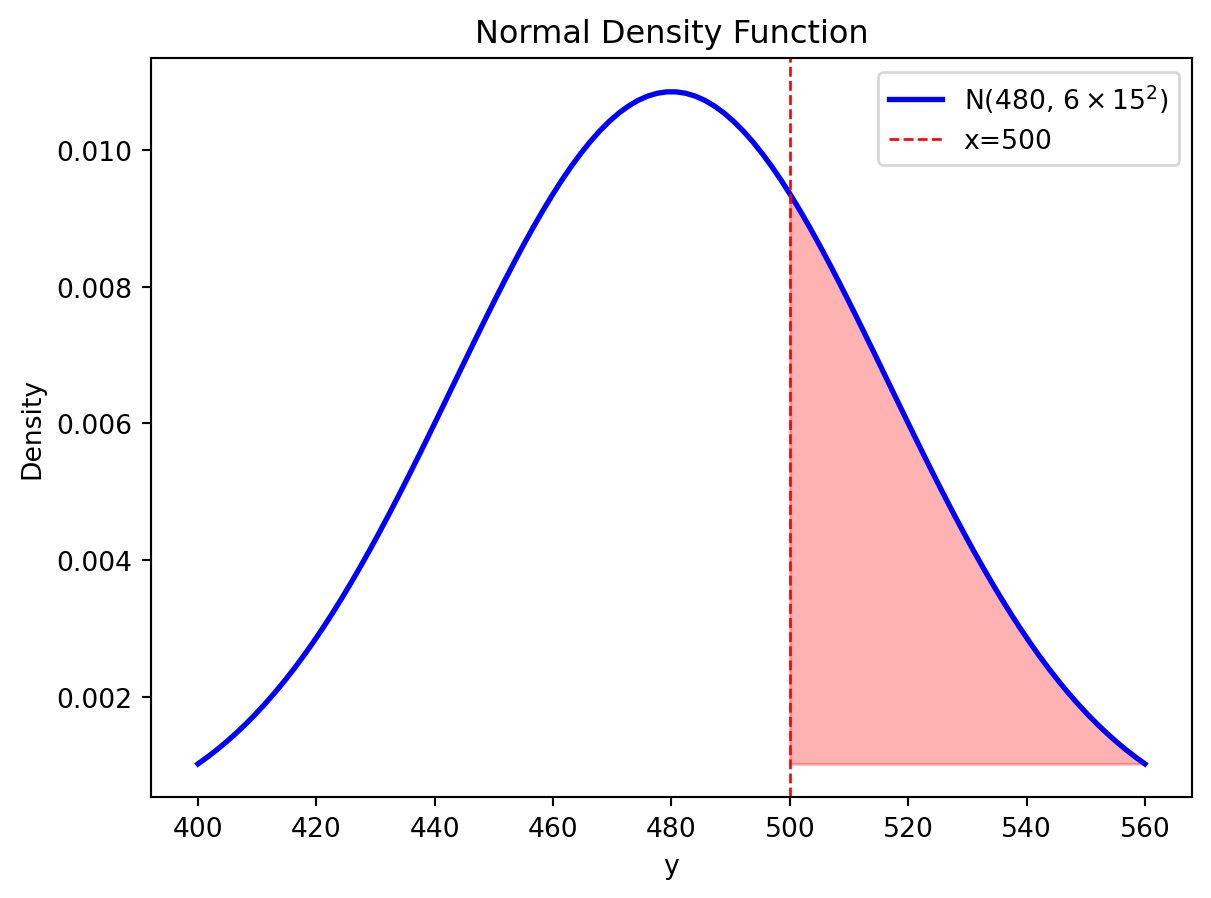

In [26]:
# Plot the density of a normal distribution with mean 480 and standard deviation 15

x = np.linspace(400, 560, 100)
avg_population_weight = 80
std_population_weight = 15

group_size = 6
group_avg_weight = avg_population_weight * group_size
group_std_weight = std_population_weight * np.sqrt(group_size)

# The normal density function
y = 1 / (group_std_weight * np.sqrt(2 * np.pi)) * np.exp(- (x - group_avg_weight)**2 / (2 * group_std_weight**2))

plt.plot(x, y, color='blue', linewidth=2, label=r'N(480, $6 \times 15^2)$')
plt.axvline(500, color='red', linestyle='dashed', linewidth=1, label='x=500')
plt.xlabel('y')
plt.ylabel('Density')
plt.title('Normal Density Function')
plt.legend()

plt.fill_betweenx(y, x, 500, where=(x >= 500), color='red', alpha=0.3)
plt.show()


In [27]:
from scipy.stats import norm

# Probability that the sum of weights is less than 500 using the normal approximation

prob_less_500 = norm.cdf(500, loc=group_avg_weight, scale=group_std_weight)

print(f'Probability that the sum is less than 500: {prob_less_500:.4f}')
print(f'Probability that the sum is over  500: {1 - prob_less_500:.4f}')

Probability that the sum is less than 500: 0.7069
Probability that the sum is over  500: 0.2931


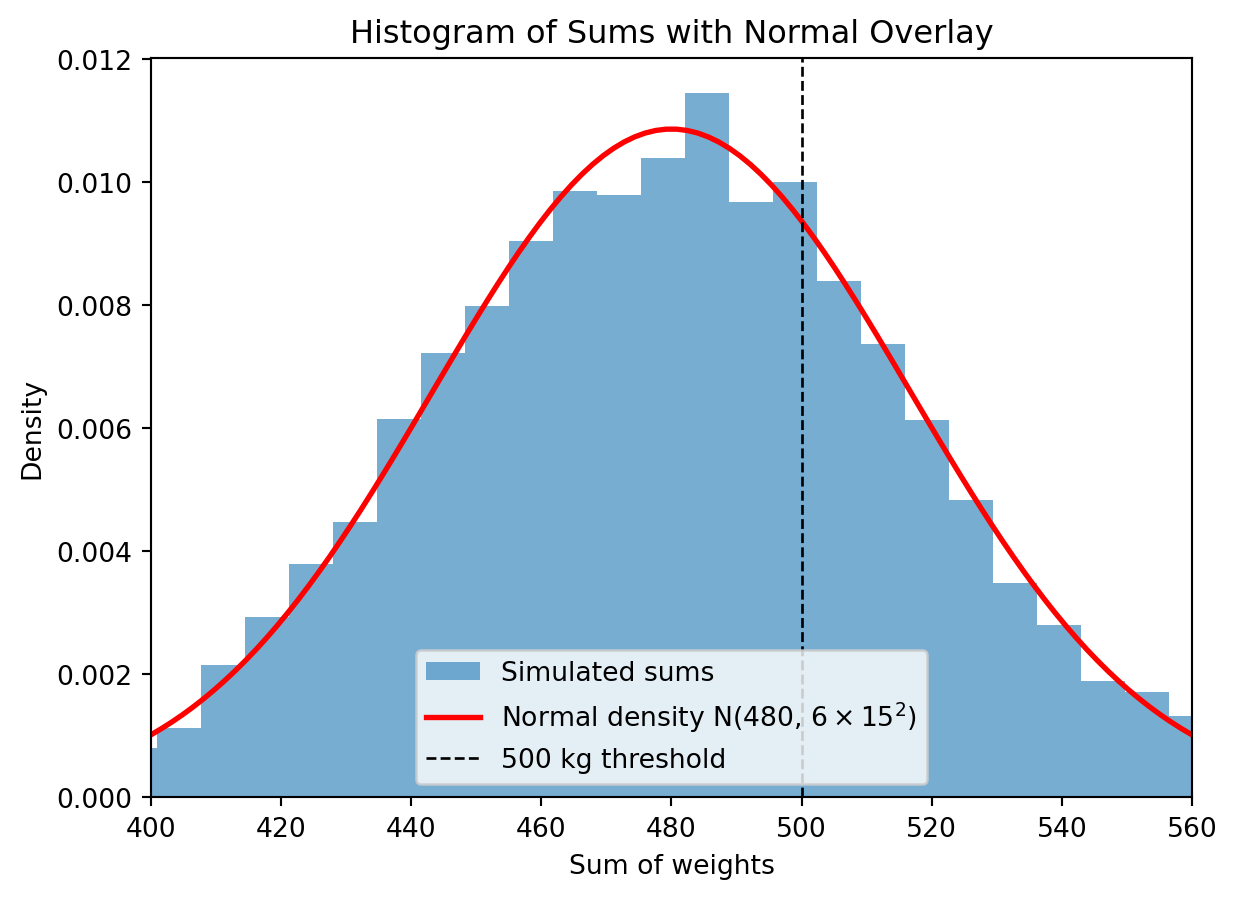

Number of times the sum exceeds 500: 2893 out of 10000


In [28]:
# Simulate selecting samples of size 6 from N(80, 15^2)
num_samples = 10000
sample_size = 6

samples = np.random.normal(avg_population_weight, std_population_weight, (num_samples, sample_size))
sums = np.sum(samples, axis=1)

# Plot histogram of the sums
plt.hist(sums, bins=40, density=True, alpha=0.6, label='Simulated sums')

# Overlay the normal density from above (mean=480, std_dev=sqrt(1350))
y_overlay = 1 / (group_std_weight * np.sqrt(2 * np.pi)) * np.exp(- (x - group_avg_weight)**2 / (2 * group_std_weight**2))
plt.plot(x, y_overlay, color='red', linewidth=2, label=r'Normal density N(480, $6 \times 15^2)$')

plt.axvline(500, color='black', linestyle='dashed', linewidth=1, label='500 kg threshold')
plt.xlabel('Sum of weights')
plt.ylabel('Density')
plt.title('Histogram of Sums with Normal Overlay')
plt.xlim(400, 560)
plt.legend()
plt.show()

# Count how many times the sum exceeds 500
exceeds_500 = np.sum(sums > 500)
print(f'Number of times the sum exceeds 500: {exceeds_500} out of {num_samples}')

In [29]:
# Compute the 0.99 quantile of the normal distribution with mean 480 and variance 6 * 15^2

quantile_99 = norm.ppf(0.99, loc=group_avg_weight, scale=group_std_weight)
quantile_99

np.float64(565.4754788341273)

# The Exponential Distribution (Optional)

:::{#exr-exponential-distribution-CDF}
## CDF of the Exponential Distribution

Calculate the CDF of the exponential distribution.
:::

:::{.callout-note collapse="true"}
## Solution (click to expand)

The CDF of the exponential distribution is given by:

$$
\begin{align*}
F(x) & = P(X \leq x) = \int_{-\infty}^{x} \lambda e^{-\lambda t} dt \\
     & = \int_{0}^{x} \lambda e^{-\lambda t} dt \\
     & = -e^{-\lambda t} \Big|_{0}^{x} \\
     & = -e^{-\lambda x} + e^{-\lambda \cdot 0} \\
     & = 1 - e^{-\lambda x}
\end{align*}
$$

:::

:::{#exr-exponential-distribution-expected-value}
## Expected Value of the Exponential Distribution

Calculate the expected value of the exponential distribution.

:::

:::{.callout-note collapse="true"}
## Solution (click to expand)

To calculate the expected value of the exponential distribution, we need to evaluate the following integral:

$$
\begin{align*}
E(X) & = \int_{-\infty}^{\infty} x \lambda e^{-\lambda x} dx = \int_{0}^{\infty} x \lambda e^{-\lambda x} dx
\end{align*}
$$

We can use integration by parts to solve this integral. The integration by parts rule is related to the product rule for differentiation.

$$
(uv)' = u'v + uv'
$$

where both $u$ and $v$ are functions of $x$ and $u'$ and $v'$ are their derivatives with respect to $x$. Integrate both sides and rearrange to get the integration by parts formula:

$$
\int (uv)' dx = \int u'v dx + \int uv' dx \implies uv = \int u'v dx + \int uv' dx \implies \int uv' dx = uv - \int u'v dx
$$


In our integral it makes sense to choose $u = \lambda x$ and $v' = e^{-\lambda x}$ because the derivative of $u$ is a constant and the integral of $v'$ is easy to calculate. Note that 

$$
\int e^{-\lambda x} = \frac{e^{-\lambda x}}{-\lambda} + C
$$ 

where $C$ is the constant of integration. Now we are ready to apply the integration by parts formula:

$$
\begin{align*}
\int \lambda x e^{-\lambda x} dx & = \lambda x \frac{e^{-\lambda x}}{-\lambda} - \int \lambda \frac{e^{-\lambda x}}{-\lambda} dx \\
& = -x e^{-\lambda x} + \int e^{-\lambda x} dx \\
& = -x e^{-\lambda x} - \frac{e^{-\lambda x}}{\lambda} + C \\
& = e^{-\lambda x} (-x - \frac{1}{\lambda}) + C
\end{align*}
$$

Now that we have the expression for the integral, we can evaluate the expected value:

$$
\begin{align*}
E(X) & = \int_{0}^{\infty} x \lambda e^{-\lambda x} dx \\
 & = e^{-\lambda x} (-x - \frac{1}{\lambda}) \Big|_{0}^{\infty} \\
 & = \lim_{x \to \infty} e^{-\lambda x} (-x - \frac{1}{\lambda}) - e^{-\lambda \cdot 0} (-0 - \frac{1}{\lambda}) \\
 & = 0 - 0 - (-0 - \frac{1}{\lambda}) \\
 & = \frac{1}{\lambda}
\end{align*}
$$

Note that the last result uses the fact that $\lim_{x \to \infty} e^{-\lambda x} = 0$ and $\lim_{x \to \infty} x e^{-\lambda x} = 0$. The latter limit can be shown by applying L'Hopital's rule.

To find the variance of the exponential distribution, we can find the second uncentered momen of the distribution (i.e., $E(X^2)$) and then use the formula $\text{Var}(X) = E(X^2) - E(X)^2$. Again,
we can use integration by parts to find the integral.

$$
\begin{align*}
E(X^2) & = \int_{0}^{\infty} x^2 \lambda e^{-\lambda x} dx = \\
& =  -x^2 e^{-\lambda x}\Big|_{0}^{\infty} + \frac{2}{\lambda} \int_{0}^{\infty} \lambda x e^{-\lambda x} dx \\
& = 0 - 0 + \frac{2}{\lambda} \frac{1}{\lambda} = \frac{2}{\lambda^2}
\end{align*}
$$

Finally, we can calculate the variance:

$$
\begin{align*}
\text{Var}(X) & = E(X^2) - E(X)^2 = \frac{2}{\lambda^2} - \frac{1}{\lambda^2} = \frac{1}{\lambda^2}
\end{align*}
$$

:::